# Nonlinear amplitude–phase simulation: FPCA+VAR vs FAE+VAR for $K\in\{3,5,7\}$, $B\in\{10,\dots,50\}$


**Methods (both trained on the same 495 noisy curves, same $K$, same VAR(1) with intercept, ridge 1e-6).**
* FPCA: curves projected on $B$ cubic B-splines (least squares), trapezoid-weighted FPCA, first $K$ scores, VAR(1).
* FAE: $B\to128\to K\to128\to B$ (tanh), B-spline projection/revert layers with $M^{(I)}=M^{(O)}=B$.

## 1. Core code 

In [ ]:
%%writefile sim_core.py
"""Core code for the FPCA vs FAE nonlinear amplitude-phase simulation.

Simulator  : the amplitude-phase generator; phase/amplitude strengths exposed in SimCfg.
FPCA       : curves projected on B cubic B-splines, then trapezoid-weighted FPCA, K scores, VAR(1).
FAE        : B -> 128 -> K -> 128 -> B (tanh), B-spline projection / revert layers, curves centred
             and scaled by a common scalar from the chronological training sub-block only;
             reconstruction MSE + 2nd-difference smoothness; epoch chosen on a chronological
             85/15 validation split, then refit on all T curves; VAR(1) on the latent sequence.
"""
from __future__ import annotations
import math
from dataclasses import dataclass, asdict
import numpy as np
import torch

torch.set_num_threads(1)

# ------------------------------------------------------------------ basis
def bspline_basis(n_basis: int, n_time: int, degree: int = 3) -> np.ndarray:
    """Cubic B-spline basis (n_time x n_basis) on a uniform grid of [0,1], uniform interior knots."""
    tau = np.linspace(0.0, 1.0, n_time)
    p = degree
    n_int = max(n_basis - p - 1, 0)
    interior = np.linspace(0.0, 1.0, n_int + 2)[1:-1] if n_int > 0 else np.array([])
    knots = np.concatenate((np.zeros(p + 1), interior, np.ones(p + 1)))
    N = np.zeros((n_basis, n_time))
    for i in range(n_basis):
        N[i] = np.where((tau >= knots[i]) & (tau < knots[i + 1]), 1.0, 0.0)
    N[-1, tau == 1.0] = 1.0
    for k in range(1, p + 1):
        Nn = np.zeros_like(N)
        for i in range(n_basis):
            dl = knots[i + k] - knots[i]
            left = (tau - knots[i]) / dl * N[i] if dl > 0 else 0.0
            right = 0.0
            if i + 1 < n_basis:
                dr = knots[i + k + 1] - knots[i + 1]
                if dr > 0:
                    right = (knots[i + k + 1] - tau) / dr * N[i + 1]
            Nn[i] = left + right
        N = Nn
    return N.T


def trapezoid_weights(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, float); dx = np.diff(x); w = np.empty_like(x)
    w[0], w[-1] = dx[0] / 2, dx[-1] / 2; w[1:-1] = (x[2:] - x[:-2]) / 2
    return w

# ------------------------------------------------------------------ simulator
@dataclass
class SimCfg:
    seed: int = 123
    T: int = 500
    P: int = 100
    d: int = 5
    Sigma_scale: float = 0.028
    meas_noise_sd: float = 0.001
    age_min: float = 15.0
    age_max: float = 49.0
    fertility_tail_strength: float = 0.012
    # --- amplitude / phase strengths
    shift_scale: float = 0.14       # global horizontal shift amplitude
    dilation_scale: float = 0.18    # stretching / compression amplitude
    warp_scale: float = 0.08        # localised warp amplitude
    peak_width: float = 0.08        # main-peak template width
    shoulder_width: float = 0.12    # shoulder template width
    trend_scale: float = 1.0        # deterministic trend on z2
    clip_value: float = 2.0
    latent_rho: float = 0.0         # 0 = A; >0 replaces its diagonal by latent_rho
    nonlin_scale: float = 1.0       # multiplies the interaction term g(h_{t-1})
    latent_gain: float = 1.0        # multiplies the stochastic latent state before the decoder
    map_mode: str = "nonlinear"     # "nonlinear" or "linear"
    lin_n_basis: int = 12           # linear benchmark: generating basis size 
    lin_target_rho: float = 0.85
    lin_weight_sd: float = 0.8
    lin_exact_rho: bool = False     # True: rescale A 
    lin_d: int = 0                  # number of linear latent factors (0 = use d)


def _latent_A(cfg: SimCfg) -> np.ndarray:
    A = np.array([[0.60, 0.05, 0.00, 0.00, 0.00],
                  [0.00, 0.72, 0.06, 0.00, 0.00],
                  [0.00, 0.00, 0.66, 0.05, 0.00],
                  [0.00, 0.00, 0.00, 0.68, 0.06],
                  [0.03, 0.00, 0.00, 0.00, 0.62]])[:cfg.d, :cfg.d]
    if cfg.latent_rho > 0:
        A = A - np.diag(np.diag(A)) + cfg.latent_rho * np.eye(cfg.d)
    return A


def _latent_step(z, t, A, eps, cfg: SimCfg):
    """One step of h_t = A h_{t-1} + c*g(h_{t-1}) + 0.05 d_t + eps_t (vectorised over leading dims)."""
    T = cfg.T; tau = t / max(T - 1, 1)
    drift = np.array([-0.25 * (tau - .5), 1.10 * (tau - .5), .25 * np.sin(2 * np.pi * tau),
                      .20 * np.sin(np.pi * tau), .15 * np.cos(2 * np.pi * tau)])
    z0, z1, z2, z3, z4 = (z[..., i] for i in range(5))
    g = np.stack([.10 * np.tanh(z1) - .04 * np.tanh(.8 * z0 * z1),
                  .18 * np.tanh(z2) + .04 * np.tanh(z0 ** 2),
                  -.10 * np.tanh(z0) + .08 * np.tanh(.8 * z3),
                  .08 * np.sin(np.clip(z1, -3, 3)) + .04 * np.tanh(.6 * z2 * z3),
                  .06 * np.tanh(.8 * z4) + .03 * np.tanh(.6 * z1 * z2)], -1)
    return np.clip(z @ A.T + cfg.nonlin_scale * g + .05 * drift + eps, -cfg.clip_value, cfg.clip_value)


def _latent_nonlinear(cfg: SimCfg) -> np.ndarray:
    rng = np.random.default_rng(cfg.seed)
    d, T = cfg.d, cfg.T
    Sigma = cfg.Sigma_scale ** 2 * np.eye(d)
    A = _latent_A(cfg)
    Z = np.zeros((T, d)); Z[0] = rng.multivariate_normal(np.zeros(d), Sigma)
    for t in range(1, T):
        eps = rng.multivariate_normal(np.zeros(d), Sigma)
        Z[t] = _latent_step(Z[t - 1], t, A, eps, cfg)
    return Z


def oracle_forecast(cfg: SimCfg, L: int = 5, n_mc: int = 400, seed: int = 0):
    """Monte-Carlo conditional mean E[X_{T-L+h} | h_{T-L}] under the TRUE generator (nonlinear only).
    A lower bound on the achievable forecast error; used only as a design diagnostic."""
    Z = _latent_nonlinear(cfg); T0 = cfg.T - L
    rng = np.random.default_rng(seed); A = _latent_A(cfg)
    z = np.repeat(Z[T0 - 1][None], n_mc, 0); out = []
    for h in range(L):
        t = T0 + h
        z = _latent_step(z, t, A, rng.normal(size=z.shape) * cfg.Sigma_scale, cfg)
        tr_t = np.full(n_mc, np.linspace(-1, 1, cfg.T)[t])
        out.append(_decoder_nonlinear(z, cfg, tr=tr_t).mean(0))
    return np.array(out)


def _sig(x): return 1.0 / (1.0 + np.exp(-x))


def _decoder_nonlinear(Z: np.ndarray, cfg: SimCfg, tr=None) -> np.ndarray:
    T = Z.shape[0]
    u = np.linspace(0, 1, cfg.P)[None, :]
    if tr is None:
        tr = np.linspace(-1, 1, T)
    tr = cfg.trend_scale * tr
    Z = cfg.latent_gain * Z
    z1, z2, z3, z4, z5 = (Z[:, i] for i in range(5))
    z1 = z1 - 0.20 * tr; z2 = z2 + 1.00 * tr
    amp = 0.07 + 0.07 * _sig(z1 - 0.6 * z2)
    sh_amp = 0.16 * _sig(1.1 * z4 + 0.5 * z5)
    tail_amp = cfg.fertility_tail_strength * _sig(1.1 * z5 + 0.5 * z4)
    shift = cfg.shift_scale * np.tanh(1.4 * z2 - 0.7 * z3 + 0.3 * z1 * z4)[:, None]
    dil = 1.0 + cfg.dilation_scale * np.tanh(1.1 * z3 + 0.3 * z5)[:, None]
    lw = (cfg.warp_scale * np.tanh(1.3 * z4 - 0.6 * z2 + 0.2 * z1 * z5)[:, None]
          * np.exp(-0.5 * ((u - 0.48) / 0.16) ** 2) * np.sin(np.pi * (u - 0.15)))
    us = np.clip(0.5 + (u - shift + lw - 0.5) / dil, -0.2, 1.2)
    main = np.exp(-0.5 * ((us - 0.38) / cfg.peak_width) ** 2)
    shoulder = np.exp(-0.5 * ((us - 0.58) / cfg.shoulder_width) ** 2)
    tail = _sig((us - 0.62) / 0.04) * np.exp(-np.clip(us - 0.62, 0, None) / 0.13)
    X = amp[:, None] * main + (sh_amp * amp)[:, None] * shoulder + tail_amp[:, None] * tail
    return np.clip(X, 0.0, None)


def _linear_benchmark(cfg: SimCfg) -> np.ndarray:
    """Linear benchmark: latent VAR(1) (A ~ N(0,0.15^2), shrunk if rho(A) > target_rho),
    mapped linearly (d -> 20 -> lin_n_basis, weights N(0, lin_weight_sd^2), zero bias, identity
    activation) to B-spline coefficients on [0,1]."""
    rng = np.random.default_rng(cfg.seed)
    d, T = (cfg.lin_d or cfg.d), cfg.T
    Sigma = cfg.Sigma_scale ** 2 * np.eye(d)
    A = rng.normal(size=(d, d)) * 0.15
    rho = np.max(np.abs(np.linalg.eigvals(A)))
    if (cfg.lin_exact_rho or rho > cfg.lin_target_rho) and rho > 1e-12:
        A = A * (cfg.lin_target_rho / rho)
    Z = np.zeros((T, d)); Z[0] = rng.multivariate_normal(np.zeros(d), Sigma)
    for t in range(1, T):
        Z[t] = A @ Z[t - 1] + rng.multivariate_normal(np.zeros(d), Sigma)
    rw = np.random.default_rng(cfg.seed + 7)
    W1 = rw.normal(size=(d, 20)) * cfg.lin_weight_sd
    W2 = rw.normal(size=(20, cfg.lin_n_basis)) * cfg.lin_weight_sd
    Bg = bspline_basis(cfg.lin_n_basis, cfg.P)
    return (Z @ W1 @ W2) @ Bg.T


def simulate(cfg: SimCfg):
    if cfg.map_mode == "nonlinear":
        Xc = _decoder_nonlinear(_latent_nonlinear(cfg), cfg)
    else:
        Xc = _linear_benchmark(cfg)
    rng = np.random.default_rng(cfg.seed + 999)
    Xn = Xc + cfg.meas_noise_sd * rng.normal(size=Xc.shape)
    u = (np.linspace(cfg.age_min, cfg.age_max, cfg.P) if cfg.map_mode == "nonlinear"
         else np.linspace(0.0, 1.0, cfg.P))
    return u, Xc.astype(np.float64), Xn.astype(np.float64)

# ------------------------------------------------------------------ metrics, VAR
def rel_mse(xhat, xref):
    return float(np.mean((xhat - xref) ** 2) / max(np.var(xref), 1e-300))


def fit_var1(H, ridge=1e-6):
    X = np.hstack([np.ones((len(H) - 1, 1)), H[:-1]]); Y = H[1:]
    Bm = np.linalg.solve(X.T @ X + ridge * np.eye(X.shape[1]), X.T @ Y)
    return Bm[0], Bm[1:].T


def forecast_var1(h_last, b, A, steps):
    out, h = [], h_last.copy()
    for _ in range(steps):
        h = b + A @ h; out.append(h)
    return np.array(out)

# ------------------------------------------------------------------ FPCA on a B-dim basis
def fpca_B(Xtr: np.ndarray, u: np.ndarray, K: int, B: int, steps: int, ridge=1e-6):
    """Smooth curves on B cubic B-splines (least squares), weighted FPCA, VAR(1) forecast."""
    Phi = bspline_basis(B, Xtr.shape[1])
    S = Phi @ np.linalg.solve(Phi.T @ Phi, Phi.T)          # hat matrix J x J
    Xs = Xtr @ S.T
    w = trapezoid_weights(u); sw = np.sqrt(w)
    mu = Xs.mean(0); Xc = Xs - mu
    _, _, Vt = np.linalg.svd(Xc * sw, full_matrices=False)
    phi = (Vt[:K] / sw)                                      # K x J, orthonormal in L2(w)
    phi /= np.sqrt((phi ** 2 * w).sum(1, keepdims=True))
    H = (Xc * w) @ phi.T
    recon = mu + H @ phi
    b, A = fit_var1(H, ridge)
    fore = mu + forecast_var1(H[-1], b, A, steps) @ phi
    return recon, fore

# ------------------------------------------------------------------ batched FAE
@dataclass
class FaeCfg:
    epochs: int = 900
    batch_size: int = 64
    lr: float = 7e-4
    weight_decay: float = 1e-6
    init_weight_sd: float = 0.06
    smooth_lambda: float = 2e-4
    split_rate: float = 0.85
    hidden: int = 128
    eval_every: int = 25
    seed: int = 743


def _init_params(R, B, K, H, sd, gen):
    def W(i, o): return (torch.randn(R, i, o, generator=gen) * sd).requires_grad_()
    def b(o): return torch.zeros(R, 1, o).requires_grad_()
    return [W(B, H), b(H), W(H, K), b(K), W(K, H), b(H), W(H, B), b(B)]


def _forward(p, feat):
    W1, b1, W2, b2, W3, b3, W4, b4 = p
    h = torch.tanh(torch.bmm(feat, W1) + b1)
    z = torch.bmm(h, W2) + b2
    h2 = torch.tanh(torch.bmm(z, W3) + b3)
    coef = torch.bmm(h2, W4) + b4
    return z, coef


def _decode(p, z):
    _, _, _, _, W3, b3, W4, b4 = p
    return torch.bmm(torch.tanh(torch.bmm(z, W3) + b3), W4) + b4


def _d2(coef):
    d = coef[..., 2:] - 2 * coef[..., 1:-1] + coef[..., :-2]
    return (d ** 2).sum(-1).mean(-1)          # per replicate


def _train(Xs, Pmat, Brev, K, cfg, n_epochs, gen, val=None, snap_epochs=None):
    """Train R independent FAEs on Xs (R x n x J). Returns params and/or per-rep snapshots."""
    R, n, J = Xs.shape; B = Pmat.shape[1]
    p = _init_params(R, B, K, cfg.hidden, cfg.init_weight_sd, gen)
    opt = torch.optim.Adam(p, lr=cfg.lr, weight_decay=cfg.weight_decay)
    feat_all = Xs @ Pmat                                   # R x n x B (projection is linear)
    hist = []; best = torch.full((R,), float("inf")); best_ep = torch.zeros(R, dtype=torch.long)
    snaps = [None] * R
    want = None if snap_epochs is None else snap_epochs.clone()
    for ep in range(1, n_epochs + 1):
        perm = torch.argsort(torch.rand(R, n, generator=gen), dim=1)
        for idx in perm.split(cfg.batch_size, dim=1):
            ix = idx.unsqueeze(-1)
            f = torch.gather(feat_all, 1, ix.expand(-1, -1, B))
            x = torch.gather(Xs, 1, ix.expand(-1, -1, J))
            opt.zero_grad()
            _, coef = _forward(p, f)
            xhat = coef @ Brev.T
            loss = (((xhat - x) ** 2).mean((1, 2)) + cfg.smooth_lambda * _d2(coef)).sum()
            loss.backward(); opt.step()
        if val is not None and (ep == 1 or ep % cfg.eval_every == 0 or ep == n_epochs):
            Xv, fv = val
            with torch.no_grad():
                _, cv = _forward(p, fv)
                vm = ((cv @ Brev.T - Xv) ** 2).mean((1, 2))
            imp = vm < best; best = torch.where(imp, vm, best)
            best_ep = torch.where(imp, torch.tensor(ep), best_ep); hist.append((ep, vm.numpy().copy()))
        if want is not None:
            hit = (want == ep).nonzero().flatten().tolist()
            for r in hit:
                snaps[r] = [t[r:r + 1].detach().clone() for t in p]
    return p, best_ep, hist, snaps


def fae_fit_forecast(Xtr_list, u, K, B, steps, cfg: FaeCfg, ridge=1e-6, return_hist=False):
    """Fit R independent FAEs (one per replicate dataset) and return recon & forecasts (orig. scale)."""
    R = len(Xtr_list); n, J = Xtr_list[0].shape
    n_tr = max(8, min(int(cfg.split_rate * n), n - 1))
    # training-only scaling (chronological training sub-block)
    mus = np.stack([X[:n_tr].mean(0) for X in Xtr_list])
    scs = np.array([(X[:n_tr] - X[:n_tr].mean(0)).std() for X in Xtr_list])
    Xs = torch.tensor(np.stack([(X - m) / s for X, m, s in zip(Xtr_list, mus, scs)]), dtype=torch.float32)
    tn = torch.tensor(u, dtype=torch.float32)
    dt = tn[1:] - tn[:-1]; z0 = torch.zeros(1)
    W = 0.5 * torch.cat([z0, dt]) + 0.5 * torch.cat([dt, z0])
    Bb = torch.tensor(bspline_basis(B, J), dtype=torch.float32)
    Pmat = W[:, None] * Bb                                  # J x B  (feat = x @ Pmat)
    # stage 1: epoch selection on chronological split
    gen = torch.Generator().manual_seed(cfg.seed)
    feat_v = Xs[:, n_tr:] @ Pmat
    _, best_ep, hist, _ = _train(Xs[:, :n_tr], Pmat, Bb, K, cfg, cfg.epochs, gen, val=(Xs[:, n_tr:], feat_v))
    # stage 2: refit on all T curves, snapshot each replicate at its own selected epoch
    gen = torch.Generator().manual_seed(cfg.seed)
    _, _, _, snaps = _train(Xs, Pmat, Bb, K, cfg, int(best_ep.max()), gen, snap_epochs=best_ep)
    recon, fore = [], []
    for r in range(R):
        p = snaps[r]
        with torch.no_grad():
            z, coef = _forward(p, (Xs[r:r + 1] @ Pmat))
            rec = (coef @ Bb.T)[0].numpy()
            H = z[0].numpy().astype(np.float64)
            b, A = fit_var1(H, ridge)
            Hf = torch.tensor(forecast_var1(H[-1], b, A, steps), dtype=torch.float32)[None]
            fo = (_decode(p, Hf) @ Bb.T)[0].numpy()
        recon.append(rec * scs[r] + mus[r]); fore.append(fo * scs[r] + mus[r])
    out = dict(recon=recon, fore=fore, best_epoch=best_ep.numpy())
    if return_hist: out["hist"] = hist
    return out


def evaluate_cell(datasets, K, B, fae_cfg, L=5):
    """List of (u, Xclean, Xnoisy). Returns list of per-replicate dicts."""
    u = datasets[0][0]
    Xtr = [d[2][:-L] for d in datasets]
    res = fae_fit_forecast(Xtr, u, K, B, L, fae_cfg)
    rows = []
    for r, (uu, Xc, Xn) in enumerate(datasets):
        frec, ffor = fpca_B(Xn[:-L], u, K, B, L)
        rows.append(dict(K=K, B=B, rep=r,
                         FPCA_recon=rel_mse(frec, Xc[:-L]), FAE_recon=rel_mse(res["recon"][r], Xc[:-L]),
                         FPCA_fore=rel_mse(ffor, Xc[-L:]), FAE_fore=rel_mse(res["fore"][r], Xc[-L:]),
                         best_epoch=int(res["best_epoch"][r])))
    return rows

Overwriting sim_core.py


In [2]:
%%writefile run_cell.py
"""Run one (design, K, B, FAE config) cell over a list of seeds; write rows to JSON.
usage: python run_cell.py spec.json out.json"""
import sys, json, time
import numpy as np
import sim_core as sc

spec = json.load(open(sys.argv[1]))
sim_kw = spec["sim"]; fae_kw = spec["fae"]; K = spec["K"]; B = spec["B"]; seeds = spec["seeds"]
chunk = spec.get("chunk", 25)
t0 = time.time()
rows = []
for i in range(0, len(seeds), chunk):
    ss = seeds[i:i + chunk]
    ds = [sc.simulate(sc.SimCfg(seed=s, **sim_kw)) for s in ss]
    rr = sc.evaluate_cell(ds, K, B, sc.FaeCfg(**fae_kw))
    for r, s in zip(rr, ss):
        r["seed"] = s; r["rep"] = seeds.index(s)
    rows += rr
out = dict(spec=spec, rows=rows, seconds=time.time() - t0)
json.dump(out, open(sys.argv[2], "w"))
print("done", sys.argv[2], round(time.time() - t0, 1))

Overwriting run_cell.py


In [3]:
%%writefile post.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

FPCA_COLORS = {3: "#F5C9A6", 5: "#E0773A", 7: "#9C4317"}   # light -> dark orange
FAE_COLORS = {3: "#B9DED7", 5: "#3C9D90", 7: "#15544B"}    # light -> dark teal


def latex_table(df, metric, scenario_label="Nonlinear", caption="", label="", scale=1.0,
                K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50), digits=3, bold_best=True):
    """Paper-style table: rows K, column pairs (FPCA, FAE) per B, entries mean (sd)."""
    nB = len(B_grid)
    head = ["\\begin{table}[!t]", "\\centering",
            f"\\caption{{{caption}}}", f"\\label{{{label}}}", "\\resizebox{\\textwidth}{!}{%",
            "\\begin{tabular}{ll" + "cc" * nB + "}", "\\toprule",
            "\\multirow{2}{*}{Scenario} & \\multirow{2}{*}{\\raisebox{-3.5ex}{$K$}} & "
            + " & ".join(f"\\multicolumn{{2}}{{c}}{{$B={B}$}}" for B in B_grid) + " \\\\",
            "".join(f"\\cmidrule(lr){{{3 + 2 * i}-{4 + 2 * i}}}" for i in range(nB)),
            "& & " + " & ".join(["FPCA & FAE"] * nB) + "\\\\", "\\midrule"]
    body = []
    for j, K in enumerate(K_grid):
        cells = []
        for B in B_grid:
            sub = df[(df.K == K) & (df.B == B)]
            vals = {}
            for m in ["FPCA", "FAE"]:
                x = sub[f"{m}_{metric}"].to_numpy() * scale
                vals[m] = (x.mean(), x.std(ddof=1) if len(x) > 1 else 0.0)
            best = min(vals, key=lambda m: vals[m][0])
            for m in ["FPCA", "FAE"]:
                s = f"{vals[m][0]:.{digits}f} ({vals[m][1]:.{digits}f})"
                cells.append(f"\\textbf{{{s}}}" if (bold_best and m == best) else s)
        lead = f"\\multirow{{{len(K_grid)}}}{{*}}{{{scenario_label}}}" if j == 0 else ""
        body.append(f"{lead} & ${K}$ & " + " & ".join(cells) + " \\\\")
    tail = ["\\bottomrule", "\\end{tabular}%", "}", "\\end{table}"]
    return "\n".join(head + body + tail)


def summary_table(df):
    """Medians, mean ratios and paired win rates per (K,B) — robust companion to the LaTeX table."""
    out = []
    for (K, B), s in df.groupby(["K", "B"]):
        row = dict(K=K, B=B, R=len(s))
        for t in ["recon", "fore"]:
            row[f"FPCA_{t}_median"] = s[f"FPCA_{t}"].median()
            row[f"FAE_{t}_median"] = s[f"FAE_{t}"].median()
            row[f"{t}_ratio_FPCA/FAE (median)"] = row[f"FPCA_{t}_median"] / row[f"FAE_{t}_median"]
            row[f"FAE_wins_{t} (%)"] = 100 * np.mean(s[f"FAE_{t}"] < s[f"FPCA_{t}"])
        out.append(row)
    return pd.DataFrame(out)


def _panel(ax, df, metric, K_grid, B_grid, logy):
    width = 0.12
    offs = np.linspace(-2.5, 2.5, 6) * width * 1.12
    series = [("FPCA", K, FPCA_COLORS[K]) for K in K_grid] + [("FAE", K, FAE_COLORS[K]) for K in K_grid]
    for i, B in enumerate(B_grid):
        for (m, K, col), o in zip(series, offs):
            x = df[(df.K == K) & (df.B == B)][f"{m}_{metric}"].to_numpy()
            if len(x) == 0:
                continue
            ax.boxplot(x, positions=[i + o], widths=width, patch_artist=True, showfliers=True,
                       boxprops=dict(facecolor=col, edgecolor="#333333", linewidth=0.7),
                       medianprops=dict(color="#222222", linewidth=1.0),
                       whiskerprops=dict(color="#333333", linewidth=0.7),
                       capprops=dict(color="#333333", linewidth=0.7),
                       flierprops=dict(marker="+", markersize=3, markeredgecolor="#555555", linewidth=0.5))
    ax.set_xticks(range(len(B_grid))); ax.set_xticklabels([str(b) for b in B_grid])
    ax.set_xlim(-0.6, len(B_grid) - 0.4)
    if logy:
        ax.set_yscale("log")
    ax.grid(True, axis="y", color="#E5E5E5", linewidth=0.6); ax.set_axisbelow(True)
    for i in range(len(B_grid) - 1):
        ax.axvline(i + 0.5, color="#EEEEEE", linewidth=0.6, zorder=0)


def paper_boxplot(results, K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50), logy=True, path=None):
    """results: dict scenario -> DataFrame. Panels ordered like the paper:
    row 1 reconstruction, row 2 forecast; columns = scenarios (linear, nonlinear) present."""
    scen = [s for s in ["linear", "nonlinear"] if s in results]
    letters = iter("abcd") if len(scen) == 2 else None
    fig, axes = plt.subplots(2, len(scen), figsize=(5.2 * len(scen), 6.6), squeeze=False, sharex=True)
    names = {"recon": "Reconstruction", "fore": "Forecast"}
    lab = {}
    if len(scen) == 2:
        lab = {("recon", "linear"): "a", ("recon", "nonlinear"): "b",
               ("fore", "linear"): "c", ("fore", "nonlinear"): "d"}
    else:
        L = {"linear": ("a", "c"), "nonlinear": ("b", "d")}[scen[0]]   # keep the paper's letters
        lab = {("recon", scen[0]): L[0], ("fore", scen[0]): L[1]}
    for r, metric in enumerate(["recon", "fore"]):
        for c, s in enumerate(scen):
            ax = axes[r, c]
            _panel(ax, results[s], metric, K_grid, B_grid, logy)
            ax.set_title(f"({lab[(metric, s)]}) {names[metric]} | {s.capitalize()}", fontsize=10, fontweight="bold")
            if c == 0:
                ax.set_ylabel("Relative MSE" + (" (log scale)" if logy else ""))
            if r == 1:
                ax.set_xlabel("B")
    handles = []
    for K in K_grid:
        handles += [Patch(facecolor=FPCA_COLORS[K], edgecolor="#333333", label=f"FPCA (K={K})"),
                    Patch(facecolor=FAE_COLORS[K], edgecolor="#333333", label=f"FAE (K={K})")]
    fig.legend(handles=handles, loc="lower center", ncol=len(K_grid), frameon=False,
               bbox_to_anchor=(0.5, -0.005), fontsize=9)
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    if path:
        fig.savefig(path + ".pdf", bbox_inches="tight"); fig.savefig(path + ".png", dpi=200, bbox_inches="tight")
    return fig


def latex_table_multi(results, metric, caption="", label="", scale=1.0, K_grid=(3, 5, 7),
                      B_grid=(10, 20, 30, 40, 50), digits=3, bold_best=True):
    """Paper layout with several scenario blocks (e.g. Linear then Nonlinear) separated by \\midrule."""
    parts = [latex_table(results[s], metric, s.capitalize(), caption, label, scale, K_grid, B_grid, digits, bold_best)
             for s in ["linear", "nonlinear"] if s in results]
    blocks = []
    for p in parts:
        lines = p.splitlines()
        i0 = lines.index("\\midrule") + 1; i1 = lines.index("\\bottomrule")
        blocks.append(lines[i0:i1])
    head = parts[0].splitlines()[:parts[0].splitlines().index("\\midrule") + 1]
    tail = parts[0].splitlines()[parts[0].splitlines().index("\\bottomrule"):]
    body = []
    for k, b in enumerate(blocks):
        if k: body.append("\\midrule")
        body += b
    return "\n".join(head + body + tail)

def latex_table_kb(results, metric, caption="", label="", scale=1e3, K_grid=(3, 5, 7),
                   B_grid=(10, 20, 30, 40, 50), digits=2, bold_best=True):
    """User's paper style: rows = B within each scenario block, column pairs (FPCA, FAE) per K,
    entries mean (sd); the better mean in each pair in bold."""
    nK = len(K_grid)
    L = ["\\begin{table}[!t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
         "\\scriptsize", "\\setlength{\\tabcolsep}{3pt}", "\\renewcommand{\\arraystretch}{1.1}",
         "\\begin{tabular}{@{}ll" + "cc" * nK + "@{}}", "\\toprule",
         "\\multirow{2}{*}{Scenario} & \\multirow{2}{*}{$B$} & "
         + " & ".join(f"\\multicolumn{{2}}{{c}}{{$K={K}$}}" for K in K_grid) + " \\\\",
         "".join(f"\\cmidrule(lr){{{3 + 2 * i}-{4 + 2 * i}}}" for i in range(nK)),
         "& & " + " & ".join(["FPCA & FAE"] * nK) + " \\\\", "\\midrule"]
    scen = [s for s in ["linear", "nonlinear"] if s in results]
    for si, s in enumerate(scen):
        df = results[s]
        if si: L.append("\\midrule")
        for j, B in enumerate(B_grid):
            cells = []
            for K in K_grid:
                sub = df[(df.K == K) & (df.B == B)]
                v = {m: (sub[f"{m}_{metric}"].mean() * scale, sub[f"{m}_{metric}"].std(ddof=1) * scale)
                     for m in ["FPCA", "FAE"]}
                best = min(v, key=lambda m: v[m][0])
                for m in ["FPCA", "FAE"]:
                    t = f"{v[m][0]:.{digits}f} ({v[m][1]:.{digits}f})"
                    cells.append(f"\\textbf{{{t}}}" if bold_best and m == best else t)
            lead = f"\\multirow{{{len(B_grid)}}}{{*}}{{{s.capitalize()}}}" if j == 0 else ""
            L.append(f"{lead} & ${B}$ & " + " & ".join(cells) + " \\\\")
    L += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    return "\n".join(L)


Overwriting post.py


## 2. Configuration

In [ ]:
import os, sys, json, glob, time, subprocess, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sim_core as sc, post
importlib.reload(sc); importlib.reload(post)

SCENARIO   = "nonlinear"          # "linear" also works (same FAE table)
K_GRID     = [3, 5, 7]
B_GRID     = [10, 20, 30, 40, 50]
R          = 100                  # replications
EVAL_SEEDS = list(range(20001, 20001 + R))
PILOT_SEEDS = list(range(90001, 90007))
HORIZON    = 5
CHUNK      = 25                   # replications per worker task (FAEs are trained jointly, vectorised)
N_WORKERS  = max(1, (os.cpu_count() or 2) - 1)
RESULTS_DIR = f"sim_results/{SCENARIO}"

# Data-generating process: amplitude-phase generator and two phase parameters are used.
# Linear benchmark: with a persistent latent VAR(1) (A rescaled so rho(A) = 0.98 exactly)
# and 3 latent factors, so that the curves lie exactly in a 3-dimensional linear subspace.
SIM_DESIGN = (dict(shift_scale=0.50, peak_width=0.10) if SCENARIO == "nonlinear"
              else dict(map_mode="linear", lin_exact_rho=True, lin_target_rho=0.98, lin_d=3))

# FAE candidates searched on pilot seeds, and the per-(K,B) choice.
FAE_CANDIDATES = {
 "C1": {
  "epochs": 1500,
  "batch_size": 64,
  "lr": 0.0007,
  "init_weight_sd": 0.06,
  "smooth_lambda": 0.0002
 },
 "C2": {
  "epochs": 1500,
  "batch_size": 64,
  "lr": 0.0015,
  "init_weight_sd": 0.06,
  "smooth_lambda": 0.0002
 },
 "C3": {
  "epochs": 1500,
  "batch_size": 64,
  "lr": 0.0015,
  "init_weight_sd": 0.06,
  "smooth_lambda": 1e-05
 },
 "C4": {
  "epochs": 1500,
  "batch_size": 64,
  "lr": 0.0007,
  "init_weight_sd": 0.15,
  "smooth_lambda": 0.0002
 }
}
FAE_CHOICE = {
 "3,10": "C3",
 "3,20": "C1",
 "3,30": "C4",
 "3,40": "C1",
 "3,50": "C4",
 "5,10": "C3",
 "5,20": "C1",
 "5,30": "C4",
 "5,40": "C1",
 "5,50": "C1",
 "7,10": "C3",
 "7,20": "C1",
 "7,30": "C1",
 "7,40": "C1",
 "7,50": "C1"
}   # "K,B" -> candidate

print("FAE configuration per cell:")
print(pd.Series(FAE_CHOICE).rename("candidate").to_frame().T.to_string())

FAE configuration per cell:
          3,10 3,20 3,30 3,40 3,50 5,10 5,20 5,30 5,40 5,50 7,10 7,20 7,30 7,40 7,50
candidate   C3   C1   C4   C1   C4   C3   C1   C4   C1   C1   C3   C1   C1   C1   C1


### Example of simulated curves

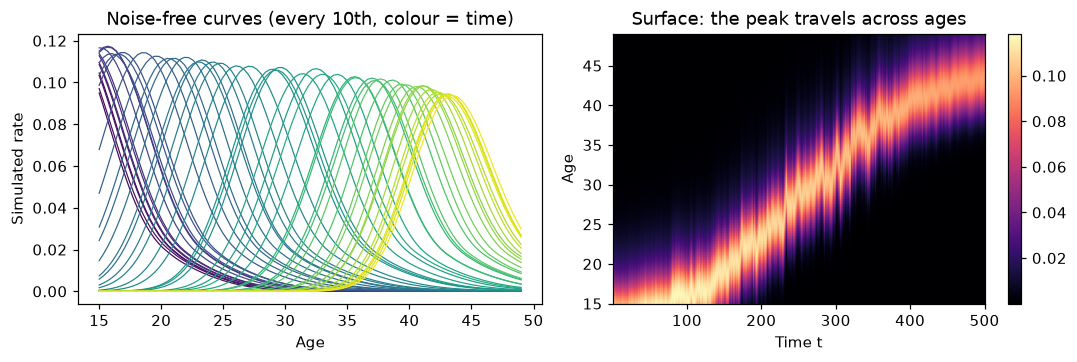

In [5]:
u, Xc, Xn = sc.simulate(sc.SimCfg(seed=EVAL_SEEDS[0], **SIM_DESIGN))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
cm = plt.cm.viridis(np.linspace(0, 1, Xc.shape[0]))
for t in range(0, Xc.shape[0], 10): ax[0].plot(u, Xc[t], color=cm[t], lw=0.8)
ax[0].set(title="Noise-free curves (every 10th, colour = time)", xlabel="Age", ylabel="Simulated rate")
im = ax[1].imshow(Xc.T, aspect="auto", origin="lower", extent=[1, Xc.shape[0], u[0], u[-1]], cmap="magma")
ax[1].set(title="Surface: the peak travels across ages", xlabel="Time t", ylabel="Age"); fig.colorbar(im, ax=ax[1])
fig.tight_layout(); plt.show()

## 3. Pilot tuning of the FAE for each $(K,B)$ (optional)

In [6]:
RUN_TUNING = False          # True: re-run the 4 candidates x 15 cells on the pilot seeds (60 tasks)

def run_tasks(tasks, n_workers=N_WORKERS):
    """tasks: list of (spec_dict, out_path). Runs run_cell.py in parallel subprocesses, skips cached outputs."""
    env = dict(os.environ, PYTHONPATH=os.getcwd(), OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
    todo = [(s, o) for s, o in tasks if not os.path.exists(o)]
    print(f"{len(tasks)-len(todo)} cached, {len(todo)} to run on {n_workers} workers"); t0 = time.time()
    running = []
    while todo or running:
        while todo and len(running) < n_workers:
            s, o = todo.pop(0); os.makedirs(os.path.dirname(o), exist_ok=True)
            json.dump(s, open(o + ".spec", "w"))
            running.append((subprocess.Popen([sys.executable, "run_cell.py", o + ".spec", o], env=env,
                                             stdout=open(o + ".log", "w"), stderr=subprocess.STDOUT), o))
        time.sleep(3)
        for p, o in list(running):
            if p.poll() is not None:
                running.remove((p, o))
                if p.returncode != 0: print("FAILED", o, open(o + ".log").read()[-500:])
    print(f"done in {(time.time()-t0)/60:.1f} min")

def load_rows(pattern):
    rows = []
    for f in sorted(glob.glob(pattern)):
        J = json.load(open(f))
        for r in J["rows"]:
            r.update(cand=J["spec"].get("cand")); rows.append(r)
    return pd.DataFrame(rows)

def select_fae(tune):
    """Per (K,B): candidate minimising mean over pilot seeds of log(recon relMSE) + log(forecast relMSE)."""
    tune = tune.assign(score=np.log(tune.FAE_recon) + np.log(tune.FAE_fore))
    s = tune.groupby(["K", "B", "cand"]).score.mean().unstack("cand")
    return s, s.idxmin(axis=1)

if RUN_TUNING:
    tasks = [(dict(sim=SIM_DESIGN, fae=f, K=K, B=B, seeds=PILOT_SEEDS, chunk=len(PILOT_SEEDS), cand=c),
              f"tuning/{SCENARIO}/{c}_K{K}_B{B}.json")
             for c, f in FAE_CANDIDATES.items() for K in K_GRID for B in B_GRID]
    run_tasks(tasks)
    scores, best = select_fae(load_rows(f"tuning/{SCENARIO}/*_K*_B*.json"))
    print(scores.round(3)); FAE_CHOICE = {f"{K},{B}": c for (K, B), c in best.items()}
    print(FAE_CHOICE)

## 4. Run the simulation grid

In [7]:
tasks = []
for K in K_GRID:
    for B in B_GRID:
        cand = FAE_CHOICE[f"{K},{B}"]
        for j in range(0, R, CHUNK):
            seeds = EVAL_SEEDS[j:j + CHUNK]
            tasks.append((dict(sim=SIM_DESIGN, fae=FAE_CANDIDATES[cand], K=K, B=B, seeds=seeds, chunk=CHUNK, cand=cand),
                          f"{RESULTS_DIR}/K{K}_B{B}_part{j // CHUNK}.json"))
run_tasks(tasks)
res = load_rows(f"{RESULTS_DIR}/K*_B*_part*.json")
res = res[res.seed.isin(EVAL_SEEDS)]
print(res.groupby(["K", "B"]).size().unstack())
res.to_csv(f"sim_results_{SCENARIO}_R{R}.csv", index=False)

60 cached, 0 to run on 11 workers
done in 0.0 min
B   10   20   30   40   50
K                         
3  100  100  100  100  100
5  100  100  100  100  100
7  100  100  100  100  100


## 5. Tables

In [8]:
SCALE, DIG = 1e3, 2
lab = SCENARIO.capitalize()
tab_rec = post.latex_table_kb({SCENARIO: res}, "recon", scale=SCALE, digits=DIG, label="tab:sim_fae_fpca_" + SCENARIO,
    caption=f"Reconstruction accuracy of FPCA and FAE under the {SCENARIO} amplitude--phase simulation benchmark. "
            f"Entries report the relMSE ($\\times 10^{{-3}}$) across {R} simulation replications, with standard deviations in parentheses.")
tab_for = post.latex_table_kb({SCENARIO: res}, "fore", scale=SCALE, digits=DIG, label="tab:sim_fae_fpca2_" + SCENARIO,
    caption=f"Out-of-sample forecasting accuracy of FPCA+VAR and FAE+VAR under the {SCENARIO} amplitude--phase simulation "
            f"benchmark. Entries report the relMSE ($\\times 10^{{-3}}$) across {R} simulation replications, with standard "
            f"deviations in parentheses. Forecasting errors are evaluated over the five held-out curves.")
open(f"table_recon_{SCENARIO}.tex", "w").write(tab_rec); open(f"table_forecast_{SCENARIO}.tex", "w").write(tab_for)
print(tab_rec); print(); print(tab_for)

def pretty(metric):
    g = res.groupby(["K", "B"])
    m = g[[f"FPCA_{metric}", f"FAE_{metric}"]].mean() * SCALE; s = g[[f"FPCA_{metric}", f"FAE_{metric}"]].std() * SCALE
    out = pd.DataFrame({mm: [f"{a:.2f} ({b:.2f})" for a, b in zip(m[f"{mm}_{metric}"], s[f"{mm}_{metric}"])]
                        for mm in ["FPCA", "FAE"]}, index=m.index)
    return out.unstack("B").swaplevel(axis=1).sort_index(axis=1, level=0)
print("\nReconstruction relMSE x 1e3"); display(pretty("recon"))
print("Forecast relMSE x 1e3"); display(pretty("fore"))
summ = post.summary_table(res); summ.to_csv(f"summary_medians_winrates_{SCENARIO}.csv", index=False)
display(summ.round(4))

\begin{table}[!t]
\centering
\caption{Reconstruction accuracy of FPCA and FAE under the nonlinear amplitude--phase simulation benchmark. Entries report the relMSE ($\times 10^{-3}$) across 100 simulation replications, with standard deviations in parentheses.}
\label{tab:sim_fae_fpca_nonlinear}
\scriptsize
\setlength{\tabcolsep}{3pt}
\renewcommand{\arraystretch}{1.1}
\begin{tabular}{@{}llcccccc@{}}
\toprule
\multirow{2}{*}{Scenario} & \multirow{2}{*}{$B$} & \multicolumn{2}{c}{$K=3$} & \multicolumn{2}{c}{$K=5$} & \multicolumn{2}{c}{$K=7$} \\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}
& & FPCA & FAE & FPCA & FAE & FPCA & FAE \\
\midrule
\multirow{5}{*}{Nonlinear} & $10$ & 105.27 (2.38) & \textbf{3.31 (0.17)} & 18.16 (0.49) & \textbf{3.25 (0.17)} & 3.94 (0.18) & \textbf{3.24 (0.17)} \\
 & $20$ & 104.75 (2.38) & \textbf{0.19 (0.02)} & 16.84 (0.56) & \textbf{0.13 (0.01)} & 1.79 (0.09) & \textbf{0.11 (0.01)} \\
 & $30$ & 104.75 (2.38) & \textbf{0.19 (0.02)} & 16.84 (0.56) & \textb

B           10                          20                          30                          40                          50               
           FAE           FPCA          FAE           FPCA          FAE           FPCA          FAE           FPCA          FAE           FPCA
K                                                                                                                                            
3  3.31 (0.17)  105.27 (2.38)  0.19 (0.02)  104.75 (2.38)  0.19 (0.02)  104.75 (2.38)  0.19 (0.02)  104.75 (2.38)  0.20 (0.02)  104.75 (2.38)
5  3.25 (0.17)   18.16 (0.49)  0.13 (0.01)   16.84 (0.56)  0.14 (0.02)   16.84 (0.56)  0.13 (0.01)   16.85 (0.56)  0.13 (0.01)   16.85 (0.56)
7  3.24 (0.17)    3.94 (0.18)  0.11 (0.01)    1.79 (0.09)  0.10 (0.01)    1.80 (0.09)  0.11 (0.01)    1.80 (0.09)  0.11 (0.01)    1.80 (0.09)

Forecast relMSE x 1e3


B           10                           20                           30                           40                           50                
           FAE            FPCA          FAE            FPCA          FAE            FPCA          FAE            FPCA          FAE            FPCA
K                                                                                                                                                 
3  7.05 (4.97)  215.12 (29.75)  5.47 (5.35)  212.38 (30.05)  5.27 (5.27)  212.39 (30.05)  5.46 (5.53)  212.39 (30.05)  5.25 (5.20)  212.39 (30.05)
5  7.45 (5.79)   50.04 (11.04)  6.02 (6.12)   52.79 (11.98)  5.91 (5.64)   52.79 (11.98)  5.94 (5.95)   52.79 (11.98)  5.92 (5.95)   52.79 (11.98)
7  7.01 (5.19)    13.93 (5.63)  5.58 (5.54)    13.25 (6.21)  5.67 (5.81)    13.26 (6.21)  5.68 (5.67)    13.26 (6.21)  5.51 (5.49)    13.26 (6.21)

,K,B,R,FPCA_recon_median,FAE_recon_median,recon_ratio_FPCA/FAE (median),FAE_wins_recon (%),FPCA_fore_median,FAE_fore_median,fore_ratio_FPCA/FAE (median),FAE_wins_fore (%)
0,3,10,100,0.1055,0.0033,31.7810,100.0,0.2139,0.0055,38.7956,100.0
1,3,20,100,0.1051,0.0002,561.2143,100.0,0.2111,0.0037,57.7709,100.0
2,3,30,100,0.1051,0.0002,573.7391,100.0,0.2111,0.0033,63.6747,100.0
3,3,40,100,0.1051,0.0002,554.0987,100.0,0.2111,0.0036,58.6295,100.0
4,3,50,100,0.1051,0.0002,550.6780,100.0,0.2111,0.0036,58.8693,100.0
5,5,10,100,0.0182,0.0033,5.5813,100.0,0.0491,0.0053,9.2333,100.0
6,5,20,100,0.0168,0.0001,134.1428,100.0,0.0510,0.0036,14.1313,100.0
7,5,30,100,0.0168,0.0001,125.3985,100.0,0.0510,0.0040,12.8716,100.0
8,5,40,100,0.0168,0.0001,132.7682,100.0,0.0510,0.0038,13.4717,100.0
9,5,50,100,0.0168,0.0001,127.6465,100.0,0.0510,0.0037,13.9461,100.0


## 6. Figure

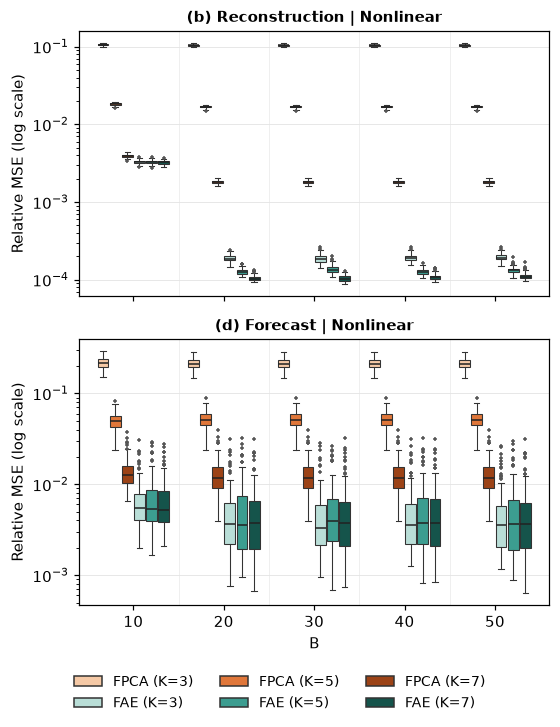

In [9]:
LOGY = True     # errors span ~3 orders of magnitude; set False for a linear axis like the original figure
fig = post.paper_boxplot({SCENARIO: res}, K_GRID, B_GRID, logy=LOGY, path=f"combined_boxplots_{SCENARIO}")
plt.show()

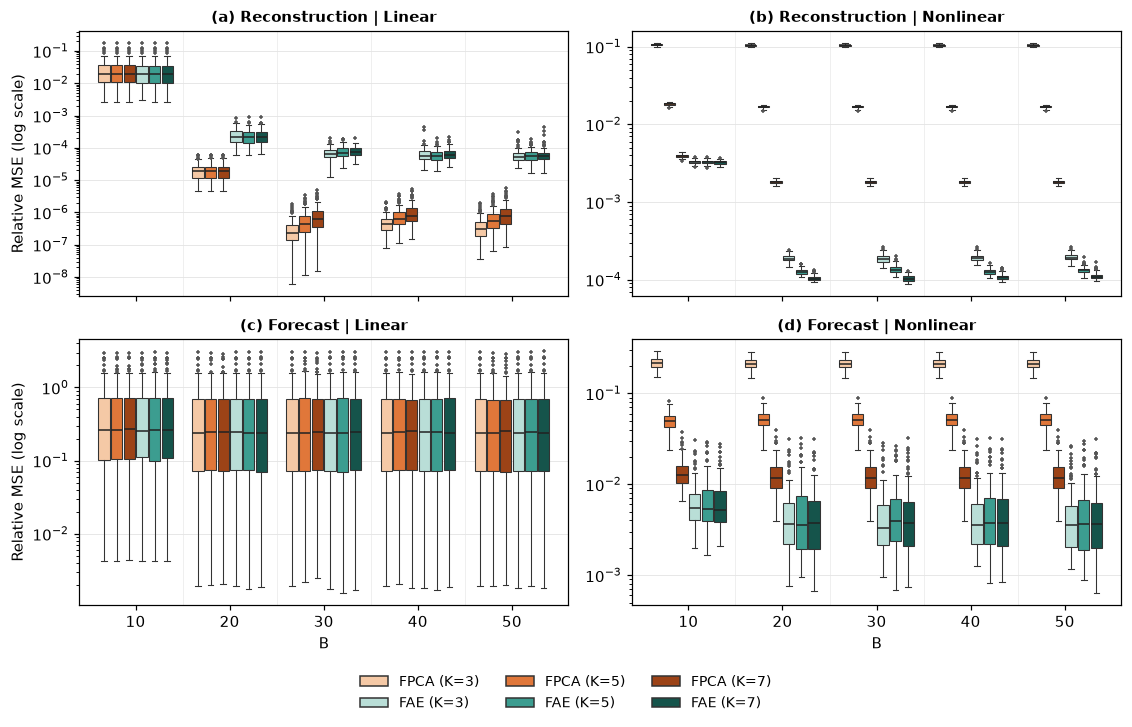

\begin{table}[!t]
\centering
\caption{Reconstruction accuracy of FPCA and FAE under the linear and nonlinear amplitude--phase simulation benchmarks. Entries report the relMSE ($\times 10^{-3}$) across 100 simulation replications, with standard deviations in parentheses.}
\label{tab:sim_fae_fpca}
\scriptsize
\setlength{\tabcolsep}{3pt}
\renewcommand{\arraystretch}{1.1}
\begin{tabular}{@{}llcccccc@{}}
\toprule
\multirow{2}{*}{Scenario} & \multirow{2}{*}{$B$} & \multicolumn{2}{c}{$K=3$} & \multicolumn{2}{c}{$K=5$} & \multicolumn{2}{c}{$K=7$} \\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}
& & FPCA & FAE & FPCA & FAE & FPCA & FAE \\
\midrule
\multirow{5}{*}{Linear} & $10$ & 28.54 (27.74) & \textbf{27.44 (27.62)} & 28.54 (27.74) & \textbf{27.45 (27.62)} & 28.54 (27.74) & \textbf{27.44 (27.63)} \\
 & $20$ & \textbf{0.02 (0.01)} & 0.25 (0.14) & \textbf{0.02 (0.01)} & 0.24 (0.14) & \textbf{0.02 (0.01)} & 0.25 (0.14) \\
 & $30$ & \textbf{0.00 (0.00)} & 0.07 (0.03) & \textbf{0.00 (0.00

,K,B,R,FPCA_recon_median,FAE_recon_median,recon_ratio_FPCA/FAE (median),FAE_wins_recon (%),FPCA_fore_median,FAE_fore_median,fore_ratio_FPCA/FAE (median),FAE_wins_fore (%),scenario
0,3,10,100,0.0201,0.0190,1.0576,27.0,0.2590,0.2560,1.0120,55.0,linear
1,3,20,100,0.0000,0.0002,0.0846,0.0,0.2417,0.2426,0.9963,45.0,linear
2,3,30,100,0.0000,0.0001,0.0036,0.0,0.2417,0.2421,0.9981,54.0,linear
3,3,40,100,0.0000,0.0001,0.0077,0.0,0.2417,0.2425,0.9964,54.0,linear
4,3,50,100,0.0000,0.0001,0.0059,0.0,0.2417,0.2404,1.0053,53.0,linear
5,5,10,100,0.0201,0.0190,1.0565,28.0,0.2659,0.2590,1.0267,53.0,linear
6,5,20,100,0.0000,0.0002,0.0866,0.0,0.2432,0.2403,1.0119,49.0,linear
7,5,30,100,0.0000,0.0001,0.0062,0.0,0.2363,0.2379,0.9932,57.0,linear
8,5,40,100,0.0000,0.0001,0.0110,0.0,0.2433,0.2423,1.0041,48.0,linear
9,5,50,100,0.0000,0.0001,0.0096,0.0,0.2414,0.2433,0.9924,51.0,linear


In [10]:
both = {}
for s in ["linear", "nonlinear"]:
    fs = glob.glob(f"sim_results/{s}/K*_B*_part*.json")
    if fs:
        d_ = load_rows(f"sim_results/{s}/K*_B*_part*.json"); both[s] = d_[d_.seed.isin(EVAL_SEEDS)]
if len(both) == 2:
    fig = post.paper_boxplot(both, K_GRID, B_GRID, logy=LOGY, path="combined_boxplots")
    plt.show()
    for metric, nm, lab_ in [("recon", "Reconstruction accuracy of FPCA and FAE", "tab:sim_fae_fpca"),
                             ("fore", "Out-of-sample forecasting accuracy of FPCA+VAR and FAE+VAR", "tab:sim_fae_fpca2")]:
        cap = (f"{nm} under the linear and nonlinear amplitude--phase simulation benchmarks. Entries report the relMSE "
               f"($\\times 10^{{-3}}$) across {R} simulation replications, with standard deviations in parentheses."
               + (" Forecasting errors are evaluated over the five held-out curves." if metric == "fore" else ""))
        t = post.latex_table_kb(both, metric, cap, lab_, scale=SCALE, digits=DIG)
        open(f"table_{metric}_both.tex", "w").write(t); print(t, "\n")
    allsumm = pd.concat([post.summary_table(v).assign(scenario=k) for k, v in both.items()])
    allsumm.to_csv("summary_medians_winrates_both.csv", index=False); display(allsumm.round(4))
else:
    print("Only", list(both), "available - run the notebook once with SCENARIO='linear' as well.")